# DATA CLEANING – SOCIAL MEDIA SENTIMENT & ENGAGEMENT ANALYSIS

This data set is about social media, specifically about "social media sentiment & engagaement analytics"
The dataset contains information about social media engagement rate,users,posts,likes,shares,comments and sentiment(positive,
negative,neutral)
rows--2260
columns--13


Column Description

1. post_id: A unique identification number assigned to each social media post.

2. timestamp: The date and time when the post was published.

3. platform: The social media platform where the post was shared.

4. user: The username of the person who created the post.

5. followers_count: The total number of followers of the user.

6. verified: Indicates whether the user's account is verified or not.

7. text: The actual text or content of the social media post.

8. hashtags: Hashtags used in the social media post.

9. country: The country associated with the user or post.

10. likes: The total number of likes received by the post.

11. retweets_shares: The total number of times the post was shared or retweeted.

12. comments: The total number of comments received by the post.

13. sentiment: Indicates the emotional tone of the post, such as Positive, Negative, or Neutral.

# import python libraries

In [1]:
import pandas as pd
import numpy as np

# load the csv dataset into python

In [2]:
df=pd.read_csv(r"C:\Users\alees\Downloads\social_media_sentiment_raw.txt")

In [3]:
df

,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2255,P100960,2023-08-29 14:24:51,Instagram,riley_7416,NaN,No,"Just checked out the new brand feature, still ...",#Sports,Canada,23,7,0.0,Neutral
2256,P100905,2024-10-01 22:42:15,TikTok,priya_1473,32524.0,Yes,"Reading more about community this week, lots t...",#Music #Climate #Business,India,95,6,17.0,Neutral
2257,P101096,2023-12-11 15:30:46,Twitter,jamie_3643,438.0,Yes,"Reading more about product this week, lots to ...",#Gaming #Business #Motivation,South Africa,33,3,3.0,Neutral
2258,P100235,2023-11-02 20:40:43,Twitter,jordan_161,66.0,Yes,This campaign launch exceeded all my expectati...,#Gaming,USA,29,8,3.0,Positive


# identify the total number of rows & columns

In [4]:
df.shape

(2260, 13)

# display all column names in dataset

In [5]:
df.columns

Index(['post_id', 'timestamp', 'platform', 'user', 'followers_count',
       'verified', 'text', 'hashtags', 'country', 'likes', 'retweets_shares',
       'comments', 'sentiment'],
      dtype='str')

# check column names,datatypes,& nulls

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2260 entries, 0 to 2259
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2260 non-null   str    
 1   timestamp        2260 non-null   str    
 2   platform         2260 non-null   str    
 3   user             2260 non-null   str    
 4   followers_count  2170 non-null   str    
 5   verified         2216 non-null   str    
 6   text             2260 non-null   str    
 7   hashtags         1472 non-null   str    
 8   country          2134 non-null   str    
 9   likes            2260 non-null   int64  
 10  retweets_shares  2260 non-null   int64  
 11  comments         2214 non-null   float64
 12  sentiment        2227 non-null   str    
dtypes: float64(1), int64(2), str(10)
memory usage: 522.7 KB


# identify the total number of missing values in each columns

In [7]:
df.isnull().sum()

post_id              0
timestamp            0
platform             0
user                 0
followers_count     90
verified            44
text                 0
hashtags           788
country            126
likes                0
retweets_shares      0
comments            46
sentiment           33
dtype: int64

# check the duplicated values

In [8]:
df.duplicated().sum()

np.int64(44)

# remove duplicate rows

In [9]:
df_clean=df.copy()
df_clean=df_clean.drop_duplicates()

# To check number of rows & columns after removing duplicates

In [10]:
df_clean.shape

(2216, 13)

# To verify that no duplicates rows remain after removing duplicates

In [11]:
df_clean.duplicated().sum()

np.int64(0)

# check followers count

In [12]:
df_clean['followers_count']

0         668.0
1          54.0
2         559.0
3        3123.0
4         549.0
         ...   
2255        NaN
2256    32524.0
2257      438.0
2258       66.0
2259    10871.0
Name: followers_count, Length: 2216, dtype: str

# To convert the timestamp column into datetime format and numerical columns into appropriate numeric data types, ensuring consistent data formats throughout the dataset

In [13]:
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'], errors='coerce')

count_columns = ['followers_count', 'likes', 'retweets_shares', 'comments']

for col in count_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

df_clean[count_columns] = df_clean[count_columns].astype('Int64')

df_clean.dtypes

post_id                       str
timestamp          datetime64[us]
platform                      str
user                          str
followers_count             Int64
verified                      str
text                          str
hashtags                      str
country                       str
likes                       Int64
retweets_shares             Int64
comments                    Int64
sentiment                     str
dtype: object

# check the number of missing values in each columns after data cleaning

In [14]:
df_clean.isnull().sum()

post_id              0
timestamp            0
platform             0
user                 0
followers_count    155
verified            44
text                 0
hashtags           768
country             82
likes                0
retweets_shares      0
comments            46
sentiment           33
dtype: int64

# To count the occurences of each value in verified columns ,including missing values 

In [15]:
df_clean['verified'].value_counts(dropna=False)

verified
No     1983
Yes     189
NaN      44
Name: count, dtype: int64

# To replace the values (missing) in verified columns with unknown

In [16]:
df_clean['verified'] = df_clean['verified'].fillna('Unknown')

In [17]:
df_clean['verified'].value_counts()

verified
No         1983
Yes         189
Unknown      44
Name: count, dtype: int64

# To count the number of records for each country including missing valuse

In [18]:
df_clean['country'].value_counts(dropna=False)

country
USA               433
India             367
UK                202
Canada            164
Australia         156
Germany           143
UAE               110
France            104
Brazil            101
Japan             101
NaN                82
South Africa       78
Mexico             49
usa                33
india              22
uk                 15
canada             12
australia           8
uae                 7
brazil              6
germany             6
japan               5
france              4
south africa        4
mexico              4
Name: count, dtype: int64

In [19]:
# 1. Fill missing values with 'Unknown'
df_clean['country'] = df_clean['country'].fillna('Unknown')

# 2. Strip whitespace and convert all country names to uppercase (usa, Usa, USA all become USA)
df_clean['country'] = df_clean['country'].str.strip().str.upper()

# 3. Check the unified value counts
print(df_clean['country'].value_counts())

country
USA             466
INDIA           389
UK              217
CANADA          176
AUSTRALIA       164
GERMANY         149
UAE             117
FRANCE          108
BRAZIL          107
JAPAN           106
UNKNOWN          82
SOUTH AFRICA     82
MEXICO           53
Name: count, dtype: int64


# capitalize the first letter of each column name in the cleaned dataset

In [20]:
df_clean.columns=df_clean.columns.str.capitalize()

# verify cleaned dataset by checking its structure,data types,and first five rows

In [21]:
df_clean.info()
df_clean.head()

<class 'pandas.DataFrame'>
Index: 2216 entries, 0 to 2259
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Post_id          2216 non-null   str           
 1   Timestamp        2216 non-null   datetime64[us]
 2   Platform         2216 non-null   str           
 3   User             2216 non-null   str           
 4   Followers_count  2061 non-null   Int64         
 5   Verified         2216 non-null   str           
 6   Text             2216 non-null   str           
 7   Hashtags         1448 non-null   str           
 8   Country          2216 non-null   str           
 9   Likes            2216 non-null   Int64         
 10  Retweets_shares  2216 non-null   Int64         
 11  Comments         2170 non-null   Int64         
 12  Sentiment        2183 non-null   str           
dtypes: Int64(4), datetime64[us](1), str(8)
memory usage: 486.9 KB


,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54,No,This event launch exceeded all my expectations...,NaN,CANADA,19,1,1,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549,Yes,This product launch exceeded all my expectatio...,NaN,INDIA,33,3,1,Positive


# To identify & display records with negative values in likes column

In [22]:
negative_likes = df_clean[df_clean['Likes'] < 0]

print("Negative Likes Records:", len(negative_likes))
negative_likes

Negative Likes Records: 8


,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment
157,P101989,2024-11-04 21:18:20,Instagram,liam_5366,2148,No,"Attended a campaign session today, some intere...",NaN,GERMANY,-1,4,3,Neutral
196,P100866,2024-03-22 22:47:38,TikTok,casey_3971,7206,No,"Just checked out the new event feature, still ...",#Art,INDIA,-1,4,8,Neutral
1205,P100777,2024-03-28 21:45:35,Facebook,wei_2287,4146,No,This product launch exceeded all my expectatio...,#Gaming #Business,INDIA,-1,5,2,Positive
1495,P100121,2023-04-03 14:21:57,Twitter,ravi_6002,1952,No,"Best app experience ever, highly recommend to ...",#Health,AUSTRALIA,-1,8,0,Positive
1566,P100938,2024-03-28 01:59:41,Twitter,casey_1025,<NA>,No,This product issue has been ignored for weeks ...,#Foodie #Health,SOUTH AFRICA,-1,3,4,Negative
1738,P102158,2023-02-25 06:26:59,Instagram,sofia_6384,866,No,Worst product experience I've had in a long ti...,#Gaming #Business,SOUTH AFRICA,-1,4,3,Negative
1948,P100621,2024-11-18 07:23:05,Twitter,liam_3656,1101,No,"Absolutely loving the new event update, this i...",#AI #News #Music,USA,-1,7,7,Positive
2135,P100077,2023-01-18 03:23:16,Twitter,noah_7352,1855,No,"Terrible customer support regarding community,...",NaN,SOUTH AFRICA,-1,9,4,Negative


# To replace invalid negative values in the likes column with missing values

In [23]:
df_clean.loc[df_clean['Likes'] < 0, 'Likes'] = np.nan

df_clean['Likes'].isnull().sum()

np.int64(8)

# check negative values again

In [24]:
(df_clean['Likes'] < 0).sum()

np.int64(0)

# To identify and display records with negative values in the Followers_count column

In [25]:
negative_followers = df_clean[df_clean['Followers_count'] < 0]

print("Negative Followers Records:", len(negative_followers))
negative_followers

Negative Followers Records: 0


,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment


# To identify and display records with negative values in the Retweets_shares column

In [26]:
negative_retweets = df_clean[df_clean['Retweets_shares'] < 0]

print("Negative Retweets Records:", len(negative_retweets))
negative_retweets

Negative Retweets Records: 0


,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment


# To identify and display records with negative values in the Comments column

In [27]:
negative_comments = df_clean[df_clean['Comments'] < 0]

print("Negative Comments Records:", len(negative_comments))
negative_comments

Negative Comments Records: 0


,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment


# outlier detection

# To generate the statistical summary of cleaned dataset and inspect the numerical columns

In [28]:
df_clean.describe()

,Timestamp,Followers_count,Likes,Retweets_shares,Comments
count,2216,2061.0,2208.0,2216.0,2170.0
mean,2023-12-31 21:37:04.212545,5893.699175,36.044384,6.612365,3.445161
min,2023-01-01 01:08:09,4.0,5.0,0.0,0.0
25%,2023-06-29 01:06:42.750000,563.0,25.0,3.0,2.0
50%,2024-01-03 02:31:47.500000,1736.0,33.0,6.0,3.0
75%,2024-07-03 09:53:09.500000,5527.0,43.25,9.0,5.0
max,2024-12-31 21:11:13,234473.0,126.0,37.0,20.0
std,NaN,12971.854291,16.394182,4.698207,2.732248


# To select numerical columns for outlier detection

In [29]:
numeric_cols = ['Followers_count', 'Likes', 'Retweets_shares', 'Comments']

# To calculate first quartile and 3rd quartile for numerical columns

In [30]:
Q1 = df_clean[numeric_cols].quantile(0.25)
Q3 = df_clean[numeric_cols].quantile(0.75)

print("Q1 Values:")
print(Q1)

print("Q3 Values:")
print(Q3)

Q1 Values:
Followers_count    563.0
Likes               25.0
Retweets_shares      3.0
Comments             2.0
Name: 0.25, dtype: Float64
Q3 Values:
Followers_count    5527.0
Likes               43.25
Retweets_shares       9.0
Comments              5.0
Name: 0.75, dtype: Float64


# To calculate the Interquartile Range (IQR) for identifying outliers

In [31]:
IQR = Q3 - Q1
print("IQR Values:")
print(IQR)

IQR Values:
Followers_count    4964.0
Likes               18.25
Retweets_shares       6.0
Comments              3.0
dtype: Float64


# calculate the lower and upper bounds for detecting outliers using the IQR method.

In [32]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:")
print(lower_bound)

print("Upper Bound:")
print(upper_bound)

Lower Bound:
Followers_count   -6883.0
Likes              -2.375
Retweets_shares      -6.0
Comments             -2.5
dtype: Float64
Upper Bound:
Followers_count    12973.0
Likes               70.625
Retweets_shares       18.0
Comments               9.5
dtype: Float64


# To identify and count outliers in each numerical column 

In [33]:
outliers = ((df_clean[numeric_cols] < lower_bound) | 
            (df_clean[numeric_cols] > upper_bound))

print("Outlier Count:")
print(outliers.sum())

Outlier Count:
Followers_count    224
Likes               88
Retweets_shares     49
Comments            74
dtype: Int64


# To replace outliers with the median values of each numerical column 

In [34]:
for col in numeric_cols:
    median_value = df_clean[col].median()
    outlier_mask = (df_clean[col] < lower_bound[col]) | (df_clean[col] > upper_bound[col])
    df_clean.loc[outlier_mask, col] = median_value

In [35]:
outliers = ((df_clean[numeric_cols] < lower_bound) | 
            (df_clean[numeric_cols] > upper_bound))

print("Outlier Count:")
print(outliers.sum())

Outlier Count:
Followers_count    0
Likes              0
Retweets_shares    0
Comments           0
dtype: Int64


# To display cleaned dataset after completing all data cleaning & outlier handling

In [36]:
df_clean

,Post_id,Timestamp,Platform,User,Followers_count,Verified,Text,Hashtags,Country,Likes,Retweets_shares,Comments,Sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54,No,This event launch exceeded all my expectations...,NaN,CANADA,19,1,1,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549,Yes,This product launch exceeded all my expectatio...,NaN,INDIA,33,3,1,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2255,P100960,2023-08-29 14:24:51,Instagram,riley_7416,<NA>,No,"Just checked out the new brand feature, still ...",#Sports,CANADA,23,7,0,Neutral
2256,P100905,2024-10-01 22:42:15,TikTok,priya_1473,1736,Yes,"Reading more about community this week, lots t...",#Music #Climate #Business,INDIA,33,6,3,Neutral
2257,P101096,2023-12-11 15:30:46,Twitter,jamie_3643,438,Yes,"Reading more about product this week, lots to ...",#Gaming #Business #Motivation,SOUTH AFRICA,33,3,3,Neutral
2258,P100235,2023-11-02 20:40:43,Twitter,jordan_161,66,Yes,This campaign launch exceeded all my expectati...,#Gaming,USA,29,8,3,Positive


# conclusion

The dataset was successfully imported and explored using Python, Pandas, and NumPy.
Initial data inspection was performed
using shape, columns, info, head, and describe functions. Missing values, 
duplicate records, and invalid values were checked and handled. Column headings
were standardized, and duplicate records were removed.

Outlier detection was performed using the IQR method, and the identified outliers were 
handled using median replacement. Final verification confirmed that no outliers remained
in the selected numerical columns.

The final cleaned dataset contains 2,216 rows and 13 columns. The dataset is now ready for further analysis.

# EDA (exploratory data analysis)

Exploratory Data Analysis (EDA) is the process of analyzing
and understanding a dataset using statistical methods and 
visualizations to identify patterns, trends, relationships, and important insights.

# To identify the number of posts available on each social media platform.

In [37]:
df_clean['Platform'].value_counts()

Platform
Twitter      680
Instagram    549
TikTok       350
Facebook     344
LinkedIn     113
TWITTER       54
INSTAGRAM     52
TIKTOK        41
FACEBOOK      27
LINKEDIN       6
Name: count, dtype: int64

# To identify the number of posts in each sentiment category.

In [38]:
df_clean['Sentiment'].value_counts()

Sentiment
Positive    883
Neutral     662
Negative    638
Name: count, dtype: int64

# To analyze sentiment distribution across different social media platforms.

In [39]:
df_clean.groupby(['Platform', 'Sentiment']).size()

Platform   Sentiment
FACEBOOK   Negative       6
           Neutral       10
           Positive      11
Facebook   Negative      94
           Neutral      104
           Positive     140
INSTAGRAM  Negative      11
           Neutral       23
           Positive      18
Instagram  Negative     167
           Neutral      171
           Positive     202
LINKEDIN   Negative       2
           Neutral        1
           Positive       3
LinkedIn   Negative      36
           Neutral       34
           Positive      43
TIKTOK     Negative      13
           Neutral       13
           Positive      14
TWITTER    Negative      14
           Neutral       20
           Positive      19
TikTok     Negative     104
           Neutral      103
           Positive     139
Twitter    Negative     191
           Neutral      183
           Positive     294
dtype: int64

# To standardize platform names by converting them into lowercase and removing extra spaces.

In [40]:
df_clean['Platform'] = df_clean['Platform'].str.strip().str.lower()

# To analyze sentiment distribution across different social media platforms after standardizing platform names.

In [42]:
df_clean['Platform'] = df_clean['Platform'].str.strip().str.capitalize()
df_clean.groupby(['Platform', 'Sentiment']).size()


Platform   Sentiment
Facebook   Negative     100
           Neutral      114
           Positive     151
Instagram  Negative     178
           Neutral      194
           Positive     220
Linkedin   Negative      38
           Neutral       35
           Positive      46
Tiktok     Negative     117
           Neutral      116
           Positive     153
Twitter    Negative     205
           Neutral      203
           Positive     313
dtype: int64

# To compare average engagement across different social media platforms.

In [47]:
df_clean.groupby('Platform')[['Likes', 'Retweets_shares', 'Comments']].mean()

,Likes,Retweets_shares,Comments
Platform,,,
Facebook,27.797297,5.059299,2.606061
Instagram,36.796327,6.720466,3.326496
Linkedin,21.218487,3.563025,1.939655
Tiktok,41.441026,7.626598,3.875
Twitter,32.875342,6.087193,3.041551


# To calculate the percentage distribution of positive, negative, and neutral sentiments.

In [50]:
(df_clean['Sentiment'].value_counts(normalize=True) * 100).round(2)

Sentiment
Positive    40.45
Neutral     30.33
Negative    29.23
Name: proportion, dtype: float64

# To compare average engagement across different sentiment categories.

In [51]:
df_clean.groupby('Sentiment')[['Likes', 'Retweets_shares', 'Comments']].mean()

,Likes,Retweets_shares,Comments
Sentiment,,,
Negative,32.581102,5.926332,3.033546
Neutral,29.221212,5.222054,2.680556
Positive,38.585227,7.187995,3.542824


# To compare average engagement between verified and non-verified users.

In [54]:
df_clean.groupby('Verified')[['Likes', 'Retweets_shares', 'Comments']].mean()

,Likes,Retweets_shares,Comments
Verified,,,
No,33.08,6.011599,3.030412
Unknown,34.659091,5.477273,3.27907
Yes,43.142857,8.613757,4.176471


# To analyze the relationship between followers count and post engagement.

In [57]:
df_clean[['Followers_count', 'Likes', 'Retweets_shares', 'Comments']].corr()

,Followers_count,Likes,Retweets_shares,Comments
Followers_count,1.000000,0.292322,0.190756,0.179048
Likes,0.292322,1.000000,0.570904,0.515814
Retweets_shares,0.190756,0.570904,1.000000,0.341675
Comments,0.179048,0.515814,0.341675,1.000000


# To compare average engagement across different countries.

In [58]:
df_clean.groupby('Country')[['Likes', 'Retweets_shares', 'Comments']].mean().round(2)

,Likes,Retweets_shares,Comments
Country,,,
AUSTRALIA,34.51,6.12,3.21
BRAZIL,32.58,6.25,2.91
CANADA,35.19,6.74,3.36
FRANCE,33.83,5.67,3.11
GERMANY,33.19,6.58,3.08
INDIA,34.2,6.13,3.2
JAPAN,35.09,6.3,2.83
MEXICO,31.92,5.43,3.21
SOUTH AFRICA,32.91,5.6,2.7


# To analyze the number of posts published over time.

In [59]:
df_clean['Timestamp'] = pd.to_datetime(df_clean['Timestamp'])
df_clean.groupby(df_clean['Timestamp'].dt.date).size()

Timestamp
2023-01-01    3
2023-01-02    4
2023-01-03    5
2023-01-04    3
2023-01-05    2
             ..
2024-12-27    3
2024-12-28    2
2024-12-29    2
2024-12-30    2
2024-12-31    4
Length: 696, dtype: int64

# To analyze monthly posting trends across different social media platforms.

In [60]:
df_clean.groupby([df_clean['Timestamp'].dt.month, 'Platform']).size()

Timestamp  Platform 
1          Facebook     45
           Instagram    50
           Linkedin      5
           Tiktok       43
           Twitter      70
2          Facebook     27
           Instagram    48
           Linkedin     11
           Tiktok       35
           Twitter      44
3          Facebook     32
           Instagram    48
           Linkedin     14
           Tiktok       25
           Twitter      61
4          Facebook     37
           Instagram    44
           Linkedin     10
           Tiktok       37
           Twitter      61
5          Facebook     26
           Instagram    49
           Linkedin      9
           Tiktok       34
           Twitter      64
6          Facebook     31
           Instagram    52
           Linkedin     14
           Tiktok       37
           Twitter      58
7          Facebook     24
           Instagram    51
           Linkedin      7
           Tiktok       37
           Twitter      61
8          Facebook     28
       

# To visualize the distribution of positive, negative, and neutral sentiments using a bar chart.

<Axes: title={'center': 'Sentiment Distribution'}, xlabel='Sentiment'>

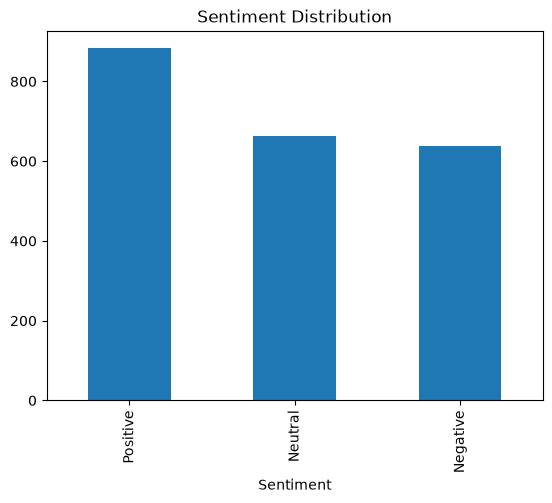

In [52]:
df_clean['Sentiment'].value_counts().plot(kind='bar', title='Sentiment Distribution')

# To visualize the percentage distribution of positive, negative, and neutral sentiments using a pie chart.

<Axes: title={'center': 'Sentiment Distribution'}>

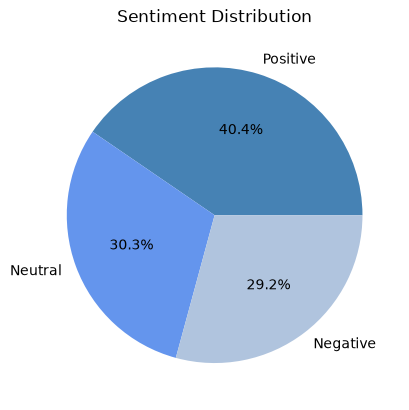

In [62]:
df_clean['Sentiment'].value_counts().plot(kind='pie', autopct='%1.1f%%', 
colors=['steelblue', 'cornflowerblue', 'lightsteelblue'], title='Sentiment Distribution')

# To visualize monthly posting trends using a line chart.

<Axes: title={'center': 'Monthly Posting Trend'}, xlabel='Timestamp'>

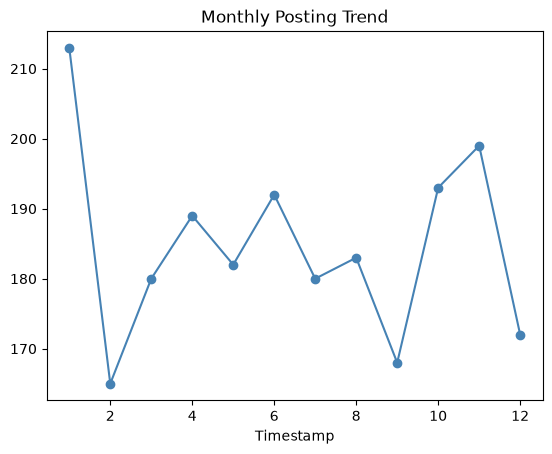

In [64]:
df_clean.groupby(df_clean['Timestamp'].dt.month).size().plot(kind='line', 
color='steelblue', marker='o', title='Monthly Posting Trend')

# To visualize the relationship between followers count and likes using a scatter plot.

<Axes: title={'center': 'Followers Count vs Likes'}, xlabel='Followers_count', ylabel='Likes'>

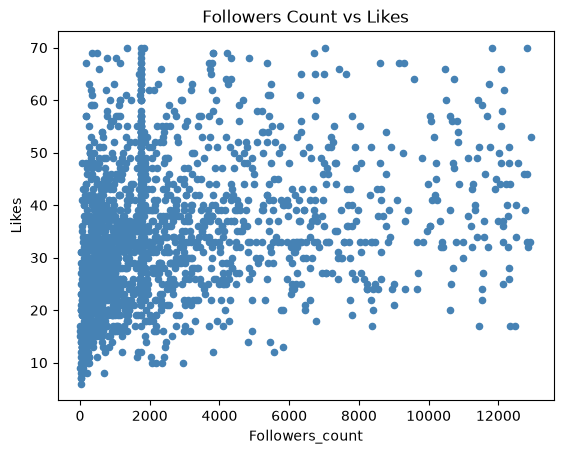

In [65]:
df_clean.plot(kind='scatter', x='Followers_count', y='Likes',
color='steelblue', title='Followers Count vs Likes')

# To visualize the distribution of likes using a histogram.

<Axes: title={'center': 'Distribution of Likes'}, ylabel='Frequency'>

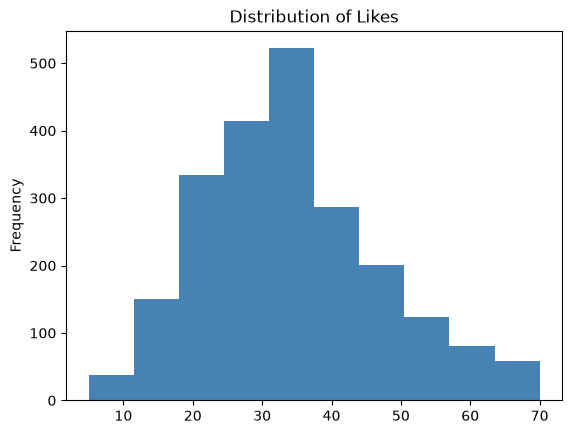

In [66]:
df_clean['Likes'].plot(kind='hist', color='steelblue', title='Distribution of Likes')

# To visualize the distribution of engagement metrics using a box plot.

<Axes: title={'center': 'Engagement Distribution'}>

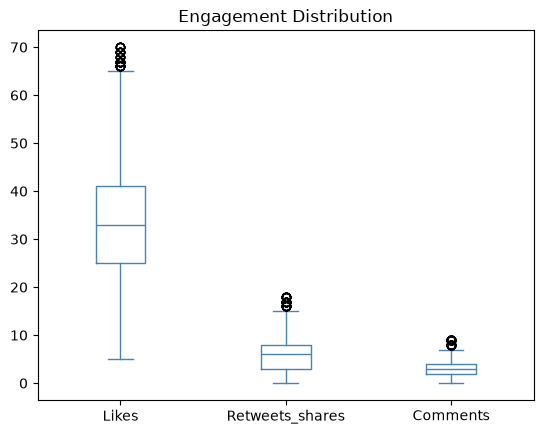

In [67]:
df_clean[['Likes', 'Retweets_shares', 'Comments']].plot(kind='box', color='steelblue', title='Engagement Distribution')

# To visualize sentiment distribution across different social media platforms using a stacked bar chart.

<Axes: title={'center': 'Sentiment Distribution by Platform'}, xlabel='Platform'>

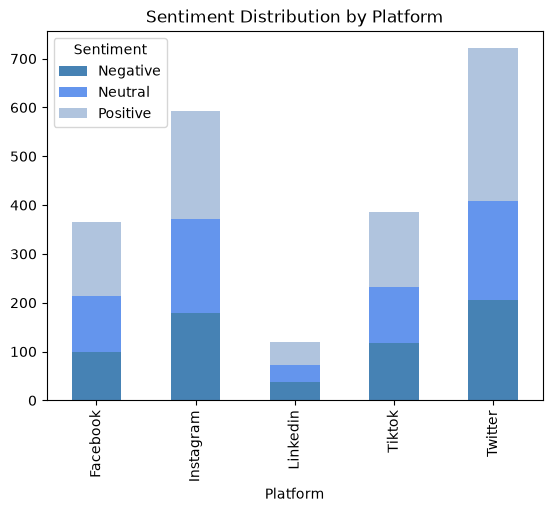

In [69]:
df_clean.groupby(['Platform', 'Sentiment']).size().unstack().plot(kind='bar', stacked=True, color=['steelblue', 
'cornflowerblue', 'lightsteelblue'], title='Sentiment Distribution by Platform')

In [ ]:
# To visualize monthly posting trends using an donut chart

<Axes: title={'center': 'Monthly Posting Trend'}>

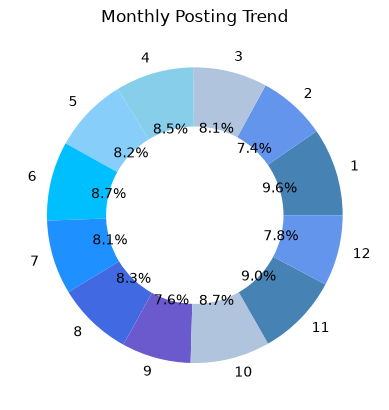

In [72]:
df_clean.groupby(df_clean['Timestamp'].dt.month).size().plot(kind='pie',
autopct='%1.1f%%', colors=['steelblue', 'cornflowerblue', 'lightsteelblue', 
'skyblue', 'lightskyblue', 'deepskyblue', 'dodgerblue',  'royalblue',
'slateblue', 'lightsteelblue', 'steelblue', 'cornflowerblue'], wedgeprops={'width':0.4}, title='Monthly Posting Trend')

# To compare average engagement across different countries using a horizontal bar chart.

<Axes: title={'center': 'Average Likes by Country'}, ylabel='Country'>

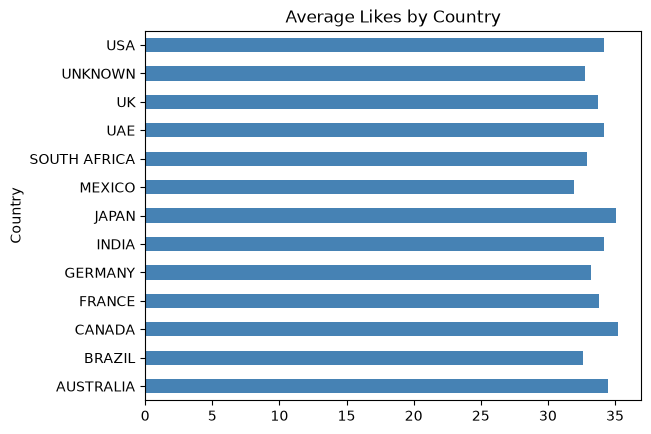

In [73]:
df_clean.groupby('Country')['Likes'].mean().plot(kind='barh', color='steelblue', title='Average Likes by Country')

# To visualize the correlation between numerical variables using a heatmap.

<Axes: >

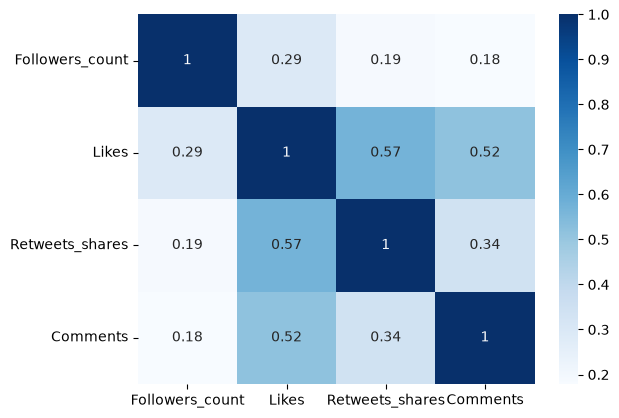

In [74]:
import seaborn as sns
sns.heatmap(df_clean[['Followers_count', 'Likes', 'Retweets_shares', 'Comments']].corr(), annot=True, cmap='Blues')

# key findings and conclusion


Through Exploratory Data Analysis (EDA), we identified the following insights from the social media dataset:

1. Analyzed the number of posts available on different social media platforms.
2. Identified the distribution of positive, negative, and neutral sentiments.
3. Compared sentiment distribution across different social media platforms.
4. Found that platform names needed standardization for accurate analysis.
5. Compared average engagement (Likes, Shares, and Comments) across platforms.
6. Analyzed the percentage distribution of different sentiment categories.
7. Found that positive sentiment posts had higher average engagement than negative and neutral posts.
8. Observed that verified users had higher average engagement than non-verified users.
9. Identified a weak positive relationship between followers count and post engagement.
10. Compared average engagement across different countries.
11. Analyzed daily and monthly posting trends across social media platforms.

Conclusion:

EDA helped us understand social media posting patterns, sentiment distribution, and user engagement. Positive sentiment posts showed higher average engagement, while followers count had a weak positive relationship with engagement. Verified users also showed higher average engagement. These findings provide useful insights into social media behavior and engagement patterns.